# KrishiNetra: AI-Powered Crop Recommendation using Data Analytics
**AICTE | IBM SkillsBuild – Data Analytics with AI Internship 2026 (BharatCares)**

**Author:** Ayush Jha  |  B.Tech CSE (Cyber Security), NIET Greater Noida

**Project:** KrishiNetra – an AI crop advisor built on soil and weather data.

**Problem:** Choosing the wrong crop for the soil and weather conditions of a field lowers yield and wastes inputs. This project analyses soil nutrients (N, P, K, pH) and climate (temperature, humidity, rainfall) and trains machine-learning models that recommend the most suitable crop.

**Workflow:** Load data → Clean → Explore (EDA) → Feature engineering → Train & compare models → Evaluate → Interpret → Predict.

## 1. Setup

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)

## 2. Load the dataset
Dataset: **Crop Recommendation Dataset** (Kaggle, by Atharva Ingle) – <https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset>

The notebook first looks for `Crop_recommendation.csv` in the same folder (download it from Kaggle). If it is not found, it falls back to a public GitHub mirror of the same data so the notebook runs end-to-end without manual steps.

In [2]:
LOCAL_FILE = "Crop_recommendation.csv"
MIRROR_URL = "https://raw.githubusercontent.com/89911384/CSV-Files/refs/heads/main/crop_cleaned%20data.csv"

df = pd.read_csv(LOCAL_FILE if os.path.exists(LOCAL_FILE) else MIRROR_URL)
print("Source :", LOCAL_FILE if os.path.exists(LOCAL_FILE) else "GitHub mirror")
print("Shape  :", df.shape)
df.head()

Source : GitHub mirror
Shape  : (1815, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
3,69,37,42,23.058049,83.370118,7.073454,251.055000,rice
4,94,53,40,20.277744,82.894086,5.718627,241.974195,rice


**Feature description**

| Column | Meaning | Unit |
|---|---|---|
| N, P, K | Nitrogen, Phosphorus, Potassium content in soil | ratio / kg per ha |
| temperature | Average temperature | °C |
| humidity | Relative humidity | % |
| ph | Soil pH | 0–14 |
| rainfall | Rainfall | mm |
| label | **Target** – recommended crop | category |

## 3. Data understanding & cleaning

In [3]:
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Number of crops:", df['label'].nunique())
df.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 1815 entries, 0 to 1814
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            1815 non-null   int64  
 1   P            1815 non-null   int64  
 2   K            1815 non-null   int64  
 3   temperature  1815 non-null   float64
 4   humidity     1815 non-null   float64
 5   ph           1815 non-null   float64
 6   rainfall     1815 non-null   float64
 7   label        1815 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 113.6 KB

Missing values per column:
 N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0
Number of crops: 20


,count,mean,std,min,25%,50%,75%,max
N,1815.0,54.58,38.14,0.00,22.00,40.00,90.00,140.00
P,1815.0,44.74,22.47,5.00,25.00,45.00,62.00,95.00
K,1815.0,32.06,15.55,5.00,20.00,27.00,44.00,82.00
temperature,1815.0,25.81,4.06,15.63,23.41,25.88,28.54,36.32
humidity,1815.0,70.66,21.81,14.26,59.48,78.05,88.49,99.98
ph,1815.0,6.49,0.68,4.60,6.03,6.47,6.94,8.38
rainfall,1815.0,102.00,53.12,20.21,60.56,94.76,133.05,253.72


In [4]:
# Cleaning: strip whitespace in labels, drop duplicates / missing rows
df['label'] = df['label'].str.strip().str.lower()
before = len(df)
df = df.drop_duplicates().dropna().reset_index(drop=True)
print(f"Rows before: {before} | after cleaning: {len(df)}")

# Sanity checks on physically valid ranges
assert df['ph'].between(0, 14).all() and df['humidity'].between(0, 100).all()
print("Range checks passed.")

Rows before: 1815 | after cleaning: 1815
Range checks passed.


## 4. Exploratory Data Analysis (EDA)

### 4.1 Crop distribution

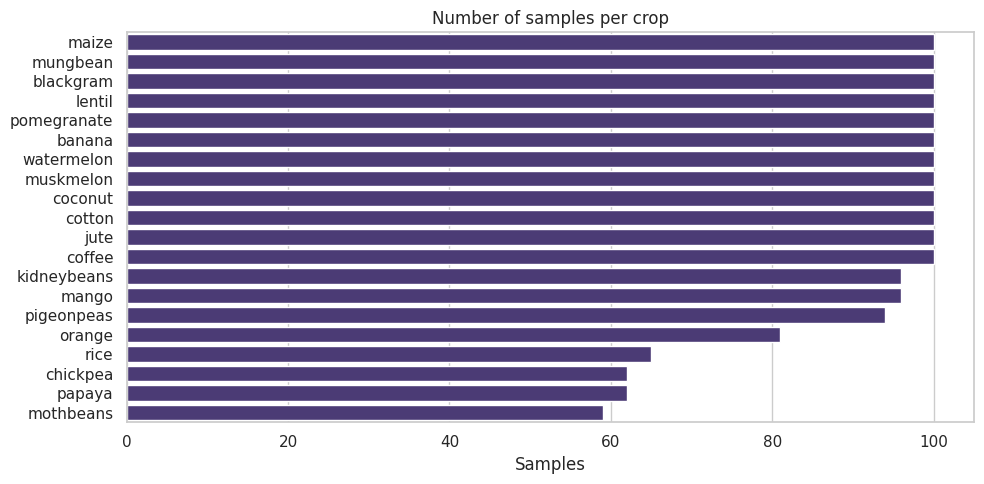

In [5]:
order = df['label'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y='label', order=order)
plt.title("Number of samples per crop"); plt.xlabel("Samples"); plt.ylabel("")
plt.tight_layout(); plt.savefig("figures/01_crop_distribution.png", dpi=150); plt.show()

### 4.2 Feature distributions

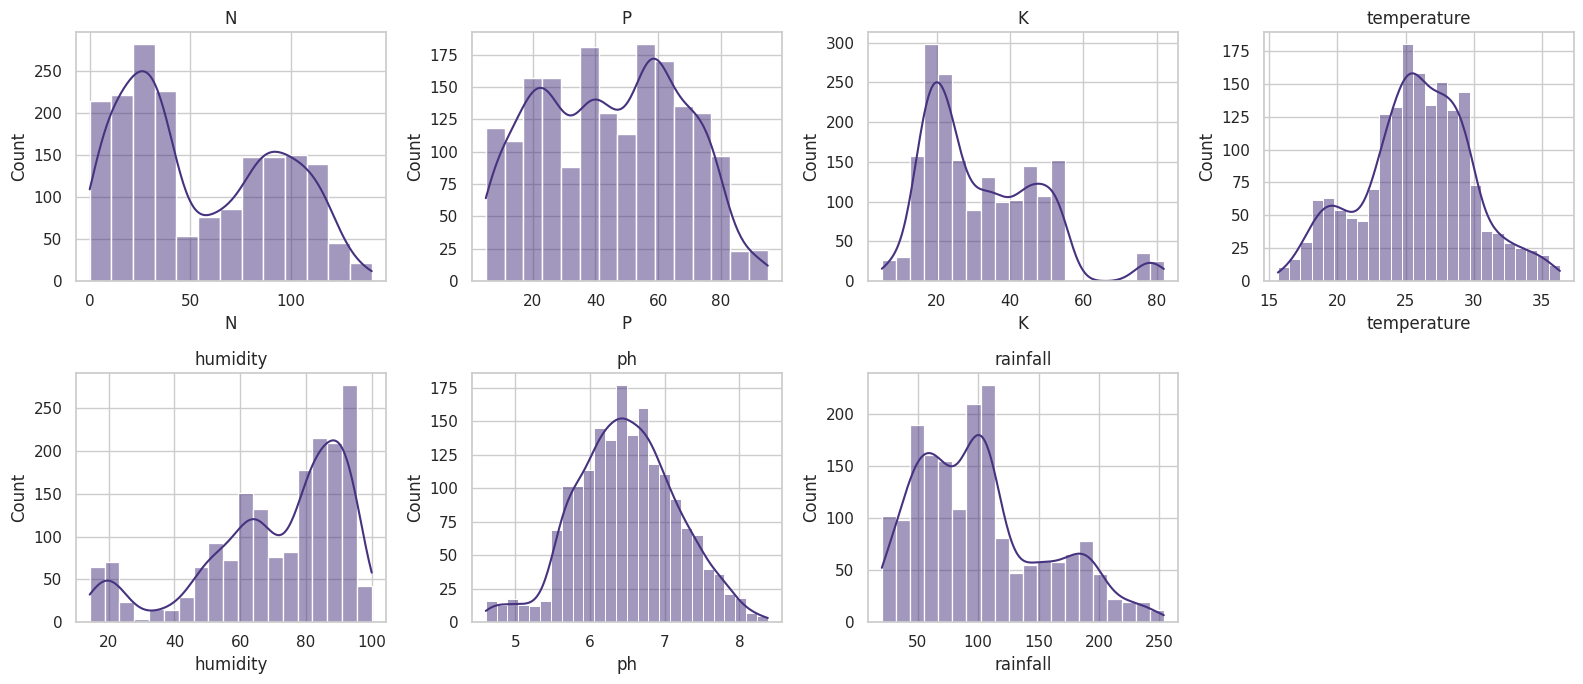

In [6]:
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.savefig("figures/02_feature_distributions.png", dpi=150); plt.show()

### 4.3 Correlation between features

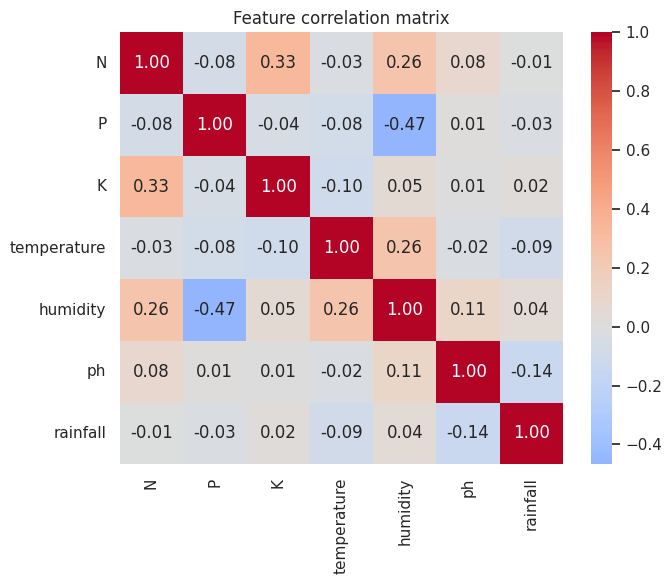

Strongest correlated pair: ('P', 'humidity') 0.47


In [7]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature correlation matrix")
plt.tight_layout(); plt.savefig("figures/03_correlation.png", dpi=150); plt.show()

corr = df[features].corr().abs().where(~np.eye(len(features), dtype=bool)).stack().sort_values(ascending=False)
print("Strongest correlated pair:", corr.index[0], round(corr.iloc[0], 2))

### 4.4 How conditions differ by crop

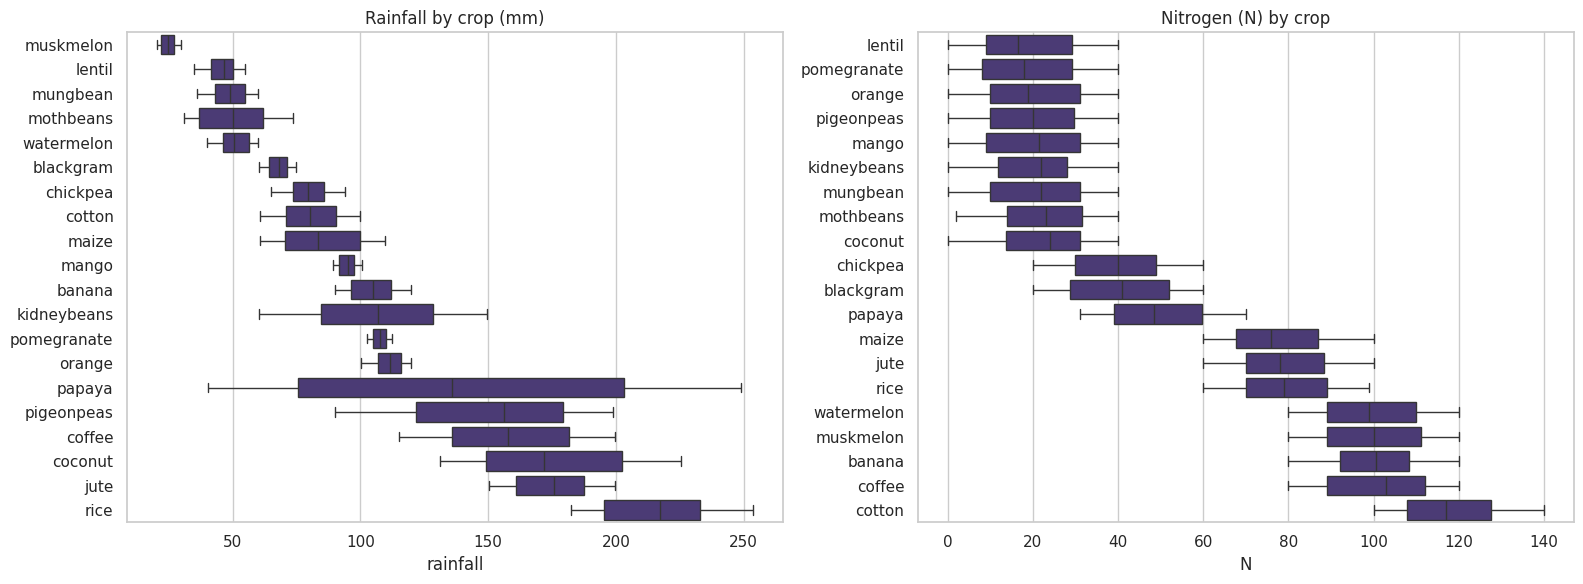

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df, y='label', x='rainfall', ax=axes[0], order=df.groupby('label')['rainfall'].median().sort_values().index)
axes[0].set_title("Rainfall by crop (mm)"); axes[0].set_ylabel("")
sns.boxplot(data=df, y='label', x='N', ax=axes[1], order=df.groupby('label')['N'].median().sort_values().index)
axes[1].set_title("Nitrogen (N) by crop"); axes[1].set_ylabel("")
plt.tight_layout(); plt.savefig("figures/04_boxplots_by_crop.png", dpi=150); plt.show()

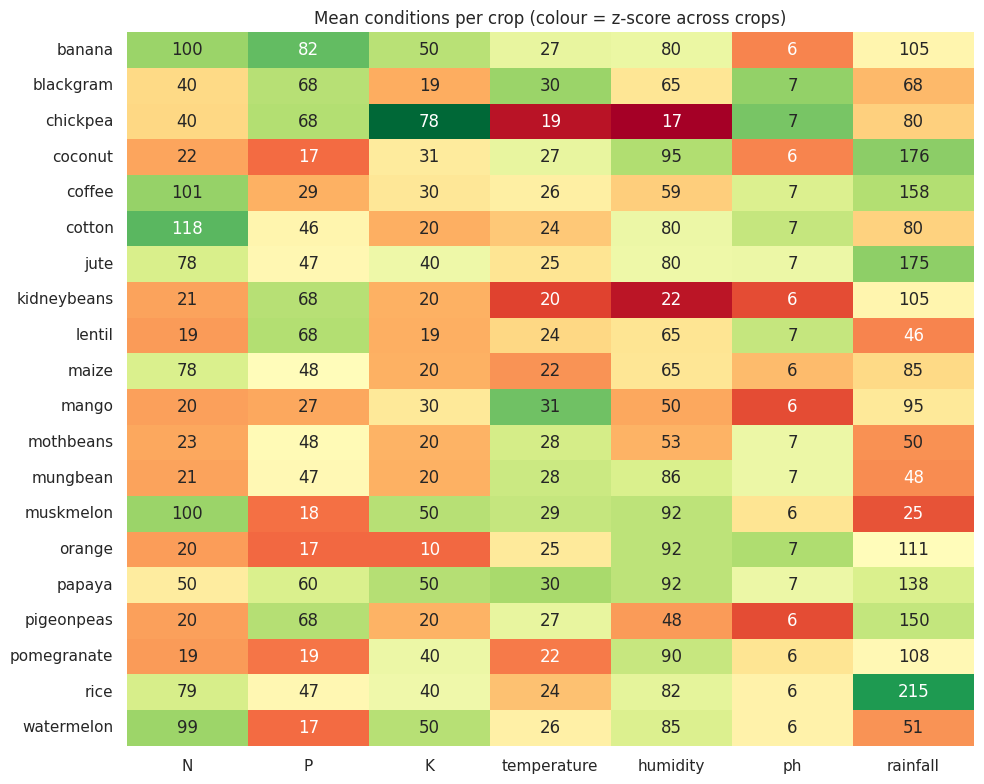

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
banana,100.2,82.0,50.0,27.4,80.4,6.0,104.6
blackgram,40.0,67.5,19.2,30.0,65.1,7.1,67.9
chickpea,39.8,68.2,78.4,18.8,16.6,7.2,79.9
coconut,22.0,16.9,30.6,27.4,94.8,6.0,175.7
coffee,101.2,28.7,29.9,25.5,58.9,6.8,158.1
cotton,117.8,46.2,19.6,24.0,79.8,6.9,80.4
jute,78.4,46.9,40.0,25.0,79.6,6.7,174.8
kidneybeans,20.7,67.5,20.0,20.3,21.6,5.8,105.4
lentil,18.8,68.4,19.4,24.5,64.8,6.9,45.7


In [9]:
# Average growing conditions per crop (a quick "crop profile" table)
profile = df.groupby('label')[features].mean().round(1)
plt.figure(figsize=(10, 8))
sns.heatmap((profile - profile.mean()) / profile.std(), cmap="RdYlGn", annot=profile, fmt=".0f", cbar=False)
plt.title("Mean conditions per crop (colour = z-score across crops)")
plt.ylabel("")
plt.tight_layout(); plt.savefig("figures/05_crop_profile.png", dpi=150); plt.show()
profile.head(10)

**EDA observations**
- The data is nearly balanced across crops, so plain accuracy is a fair metric (macro-F1 is also reported).
- Rainfall and humidity separate crops strongly (e.g. rice and coconut need far more rainfall than chickpea or lentil).
- Correlations between features are mostly weak. The strongest are humidity vs. phosphorus (negative, about -0.47) and nitrogen vs. potassium (about 0.33), so there is little redundancy among the inputs.

## 5. Feature engineering

In [10]:
def add_features(d):
    d = d.copy()
    d['NPK_total'] = d['N'] + d['P'] + d['K']
    d['N_to_K']    = d['N'] / (d['K'] + 1)
    d['P_to_K']    = d['P'] / (d['K'] + 1)
    d['moisture_index'] = d['humidity'] * d['rainfall'] / 100
    return d

df_fe = add_features(df)
X = df_fe.drop(columns='label')
y = df_fe['label']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1452, 11) | Test: (363, 11)


## 6. Model training & comparison (5-fold cross-validation)

In [11]:
models = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=2000))]),
    "KNN":                 Pipeline([("sc", StandardScaler()), ("m", KNeighborsClassifier(n_neighbors=5))]),
    "Decision Tree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    rows.append({"Model": name, "CV Accuracy (mean)": scores.mean(), "CV Std": scores.std()})
cv_results = pd.DataFrame(rows).sort_values("CV Accuracy (mean)", ascending=False).reset_index(drop=True)
cv_results.round(4)

,Model,CV Accuracy (mean),CV Std
0,Random Forest,0.9897,0.0081
1,Decision Tree,0.9738,0.0051
2,Gradient Boosting,0.9731,0.0080
3,Logistic Regression,0.9704,0.0060
4,KNN,0.9642,0.0035


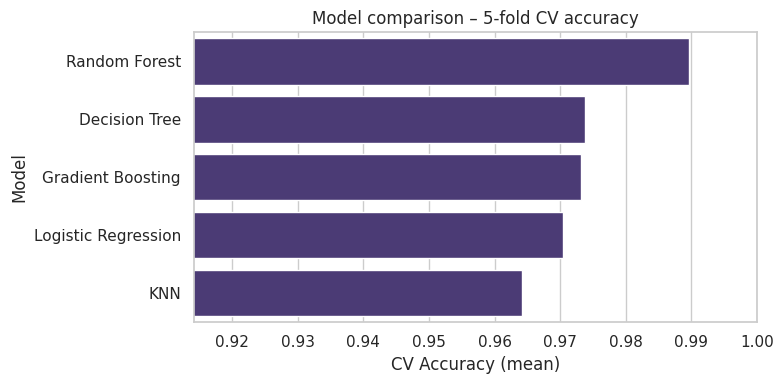

In [12]:
plt.figure(figsize=(8, 4))
sns.barplot(data=cv_results, y="Model", x="CV Accuracy (mean)")
plt.xlim(cv_results["CV Accuracy (mean)"].min() - 0.05, 1.0)
plt.title("Model comparison – 5-fold CV accuracy")
plt.tight_layout(); plt.savefig("figures/06_model_comparison.png", dpi=150); plt.show()

## 7. Hyperparameter tuning of the best model family (Random Forest)

In [13]:
param_grid = {"n_estimators": [200, 400], "max_depth": [None, 20], "min_samples_split": [2, 4]}
grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                    param_grid, cv=3, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best params :", grid.best_params_)
print("Best CV acc :", round(grid.best_score_, 4))
best_model = grid.best_estimator_

Best params : {'max_depth': None, 'min_samples_split': 4, 'n_estimators': 200}
Best CV acc : 0.9869


## 8. Final evaluation on the held-out test set

In [14]:
y_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
test_f1  = f1_score(y_test, y_pred, average="macro")
print(f"Test accuracy : {test_acc:.4f}")
print(f"Test macro-F1 : {test_f1:.4f}\n")
print(classification_report(y_test, y_pred, digits=3))

Test accuracy : 0.9917
Test macro-F1 : 0.9903

              precision    recall  f1-score   support

      banana      1.000     1.000     1.000        20
   blackgram      1.000     1.000     1.000        20
    chickpea      1.000     1.000     1.000        13
     coconut      1.000     1.000     1.000        20
      coffee      1.000     1.000     1.000        20
      cotton      1.000     1.000     1.000        20
        jute      0.905     0.950     0.927        20
 kidneybeans      1.000     1.000     1.000        19
      lentil      1.000     1.000     1.000        20
       maize      1.000     1.000     1.000        20
       mango      1.000     1.000     1.000        19
   mothbeans      1.000     1.000     1.000        12
    mungbean      1.000     1.000     1.000        20
   muskmelon      1.000     1.000     1.000        20
      orange      1.000     1.000     1.000        16
      papaya      1.000     1.000     1.000        12
  pigeonpeas      1.000     1.000 

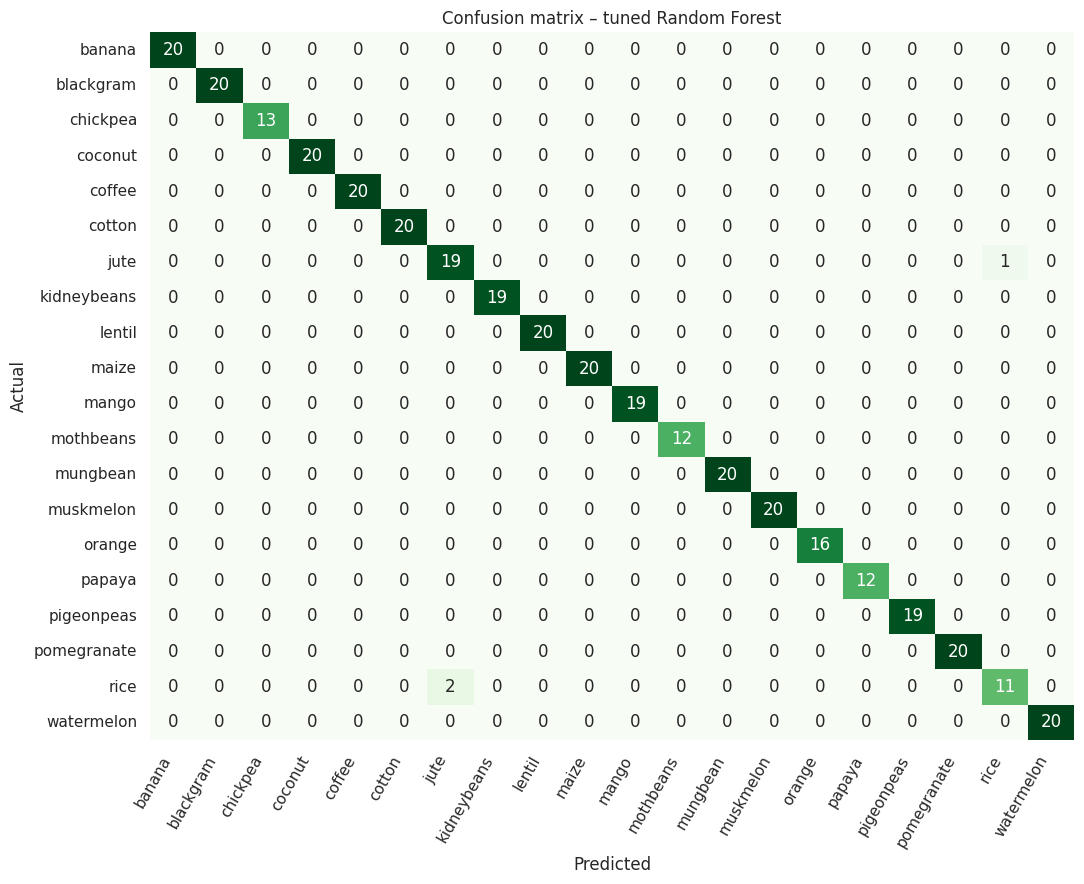

Misclassified pairs:


,actual,predicted,count
0,rice,jute,2
1,jute,rice,1


In [15]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=labels, yticklabels=labels, cbar=False)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix – tuned Random Forest")
plt.xticks(rotation=60, ha="right")
plt.tight_layout(); plt.savefig("figures/07_confusion_matrix.png", dpi=150); plt.show()

errors = pd.DataFrame({"actual": y_test.values, "predicted": y_pred})
errors = errors[errors.actual != errors.predicted].value_counts().reset_index(name="count")
print("Misclassified pairs:"); errors

## 9. Model interpretation – which factors matter most?

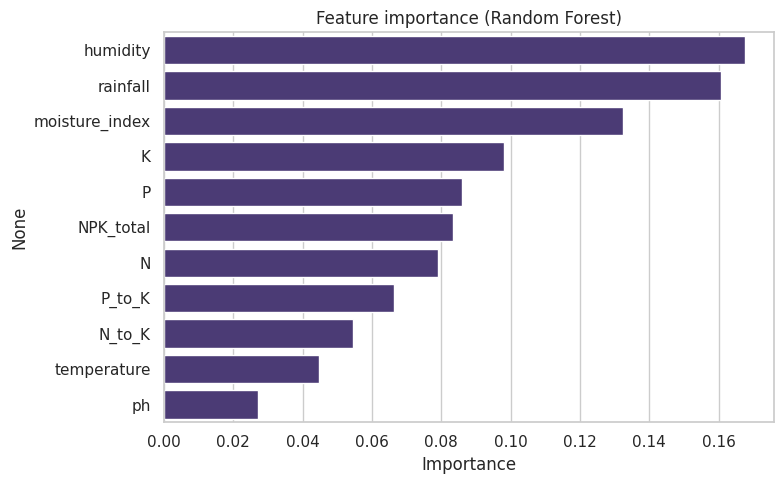

humidity          0.168
rainfall          0.161
moisture_index    0.132
K                 0.098
P                 0.086
NPK_total         0.083
N                 0.079
P_to_K            0.066
N_to_K            0.054
temperature       0.045
ph                0.027
dtype: float64

In [16]:
imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index)
plt.title("Feature importance (Random Forest)"); plt.xlabel("Importance")
plt.tight_layout(); plt.savefig("figures/08_feature_importance.png", dpi=150); plt.show()
imp.round(3)

## 10. Using the model – recommend a crop for a new field

In [17]:
def recommend_crop(N, P, K, temperature, humidity, ph, rainfall, top_k=3):
    row = pd.DataFrame([{"N": N, "P": P, "K": K, "temperature": temperature,
                         "humidity": humidity, "ph": ph, "rainfall": rainfall}])
    row = add_features(row.assign(label="x")).drop(columns="label")[X.columns]
    proba = pd.Series(best_model.predict_proba(row)[0], index=best_model.classes_)
    return proba.sort_values(ascending=False).head(top_k).round(3)

print("Example 1 – warm, humid, high rainfall field:")
print(recommend_crop(N=90, P=42, K=43, temperature=21, humidity=82, ph=6.5, rainfall=203))
print("\nExample 2 – dry, low-nitrogen field:")
print(recommend_crop(N=20, P=60, K=80, temperature=19, humidity=17, ph=7.0, rainfall=80))

Example 1 – warm, humid, high rainfall field:
rice      0.969
jute      0.028
papaya    0.002
dtype: float64

Example 2 – dry, low-nitrogen field:
chickpea    0.980
papaya      0.010
mango       0.005
dtype: float64


## 11. Save results and model

In [18]:
joblib.dump(best_model, "krishinetra_model.joblib")
results = {
    "rows": int(len(df)), "n_crops": int(df['label'].nunique()),
    "cv_results": cv_results.round(4).to_dict(orient="records"),
    "best_params": grid.best_params_,
    "test_accuracy": round(float(test_acc), 4), "test_macro_f1": round(float(test_f1), 4),
    "top_features": imp.head(5).round(3).to_dict(),
    "misclassified": int((y_test.values != y_pred).sum()), "test_size": int(len(y_test)),
}
json.dump(results, open("results.json", "w"), indent=2)
results

{'rows': 1815,
 'n_crops': 20,
 'cv_results': [{'Model': 'Random Forest',
   'CV Accuracy (mean)': 0.9897,
   'CV Std': 0.0081},
  {'Model': 'Decision Tree', 'CV Accuracy (mean)': 0.9738, 'CV Std': 0.0051},
  {'Model': 'Gradient Boosting',
   'CV Accuracy (mean)': 0.9731,
   'CV Std': 0.008},
  {'Model': 'Logistic Regression',
   'CV Accuracy (mean)': 0.9704,
   'CV Std': 0.006},
  {'Model': 'KNN', 'CV Accuracy (mean)': 0.9642, 'CV Std': 0.0035}],
 'best_params': {'max_depth': None,
  'min_samples_split': 4,
  'n_estimators': 200},
 'test_accuracy': 0.9917,
 'test_macro_f1': 0.9903,
 'top_features': {'humidity': 0.168,
  'rainfall': 0.161,
  'moisture_index': 0.132,
  'K': 0.098,
  'P': 0.086},
 'misclassified': 3,
 'test_size': 363}

## 12. Conclusions
1. Soil nutrients and weather together identify the suitable crop with very high accuracy; tree-based ensembles perform best.
2. Humidity, rainfall (and the combined moisture index) followed by potassium and phosphorus drive most predictions – these are exactly the quantities a low-cost IoT soil sensor can measure.
3. Remaining errors occur between agronomically similar crops (see confusion matrix), so a top-3 recommendation is more useful to a farmer than a single answer.

**Limitations:** the dataset is a clean, curated one – real fields have sensor noise, seasonality and market factors. **Future work:** add live sensor readings, yield and price data, and deploy as a mobile/web app.